<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/lstm_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import seaborn as sns

print("All libraries imported successfully!")

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

All libraries imported successfully!
Using device: cpu


In [ ]:
# Generate synthetic time-series dataset

np.random.seed(42)

num_samples = 2000
sequence_length = 50

X = np.zeros((num_samples, sequence_length, 1))
y = np.zeros(num_samples, dtype=np.int64)

for i in range(num_samples):

    start = np.random.uniform(10, 30)

    if i < num_samples // 2:
        # Decreasing trend
        slope = -np.random.uniform(0.08, 0.18)
        y[i] = 0

    else:
        # Increasing trend
        slope = np.random.uniform(0.08, 0.18)
        y[i] = 1

    time = np.arange(sequence_length)

    values = start + slope * time
    noise = np.random.normal(0, 0.5, sequence_length)

    X[i, :, 0] = values + noise

# Normalize each sequence relative to its first value
X = X - X[:, 0:1, :]

# Display dataset information
print("Dataset generated successfully!")
print("--------------------------------")
print("Total samples:", len(X))
print("Sequence length:", sequence_length)
print("Features per time step:", X.shape[2])
print("Increasing sequences:", np.sum(y == 1))
print("Decreasing sequences:", np.sum(y == 0))
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Dataset generated successfully!
--------------------------------
Total samples: 2000
Sequence length: 50
Features per time step: 1
Increasing sequences: 1000
Decreasing sequences: 1000
Input shape: (2000, 50, 1)
Output shape: (2000,)


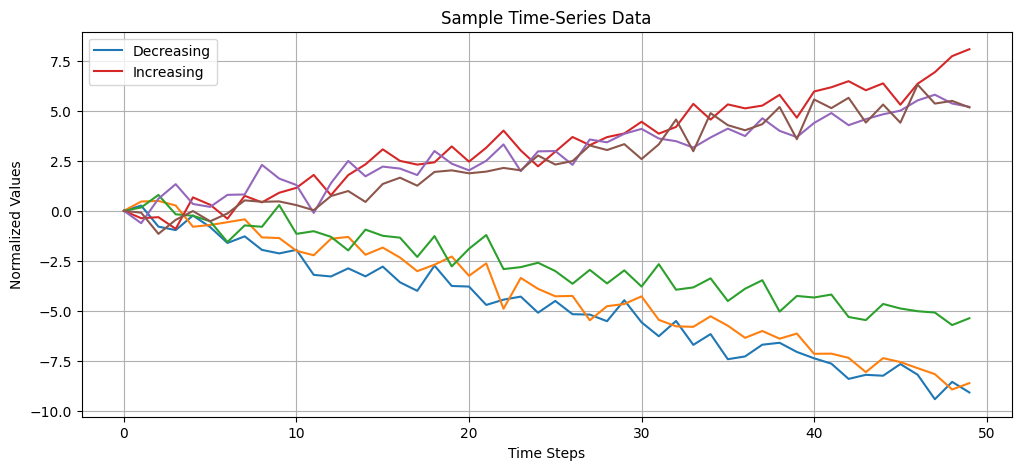

Graph displayed successfully!


In [ ]:
# Plot sample time-series sequences

plt.figure(figsize=(12, 5))

# Decreasing sequences
for i in range(3):
    plt.plot(X[i, :, 0], label="Decreasing" if i == 0 else "")

# Increasing sequences
for i in range(1000, 1003):
    plt.plot(X[i, :, 0], label="Increasing" if i == 1000 else "")

plt.title("Sample Time-Series Data")
plt.xlabel("Time Steps")
plt.ylabel("Normalized Values")
plt.legend()
plt.grid(True)
plt.show()

print("Graph displayed successfully!")

In [ ]:
# Split dataset into training and testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert NumPy arrays into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

# Create TensorDatasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Dataset split completed!")
print("--------------------------------")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Dataset split completed!
--------------------------------
Training samples: 1600
Testing samples: 400
Training batches: 50
Testing batches: 13


In [ ]:
# Define LSTM classification model

class LSTMClassifier(nn.Module):

    def __init__(self):
        super(LSTMClassifier, self).__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )

        self.fc1 = nn.Linear(64, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        # Get output from last time step
        x = output[:, -1, :]

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)

        return x


# Create model
model = LSTMClassifier().to(device)

print("LSTM Model Architecture:")
print(model)

total_params = sum(p.numel() for p in model.parameters())
print("\nTotal trainable parameters:", total_params)

LSTM Model Architecture:
LSTMClassifier(
  (lstm): LSTM(1, 64, batch_first=True)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=2, bias=True)
)

Total trainable parameters: 19298


In [ ]:
# Define loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 15

train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

print("Starting LSTM training...\n")

# Training loop
for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        predicted = torch.argmax(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    # Validation using test dataset
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in test_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)

            predicted = torch.argmax(outputs, dim=1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    test_losses.append(val_loss)
    test_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Training Loss: {epoch_loss:.4f} | "
        f"Training Accuracy: {epoch_accuracy:.2f}% | "
        f"Test Accuracy: {val_accuracy:.2f}%"
    )

print("\nTraining completed successfully!")

Starting LSTM training...

Epoch [1/15] Training Loss: 0.3125 | Training Accuracy: 94.25% | Test Accuracy: 100.00%
Epoch [2/15] Training Loss: 0.0065 | Training Accuracy: 99.94% | Test Accuracy: 100.00%
Epoch [3/15] Training Loss: 0.0012 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [4/15] Training Loss: 0.0005 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [5/15] Training Loss: 0.0002 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [6/15] Training Loss: 0.0001 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [7/15] Training Loss: 0.0001 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [8/15] Training Loss: 0.0001 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [9/15] Training Loss: 0.0000 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [10/15] Training Loss: 0.0000 | Training Accuracy: 100.00% | Test Accuracy: 100.00%
Epoch [11/15] Training Loss: 0.0000 | Training Accuracy: 100.00% | Test Accuracy: 10

Final Test Accuracy: 100.00%

Classification Report:

              precision    recall  f1-score   support

  Decreasing       1.00      1.00      1.00       200
  Increasing       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



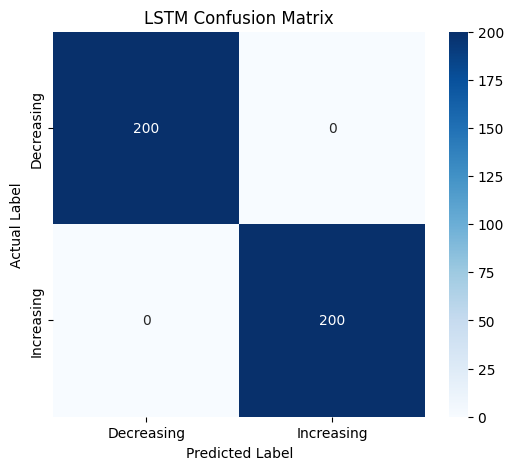

Model evaluation completed!


In [ ]:
# Evaluate the trained model

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())


# Calculate accuracy
accuracy = (
    np.array(all_predictions) == np.array(all_labels)
).mean() * 100

print("Final Test Accuracy: {:.2f}%".format(accuracy))


# Classification report
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Decreasing", "Increasing"]
))


# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Decreasing", "Increasing"],
    yticklabels=["Decreasing", "Increasing"]
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Model evaluation completed!")

Actual: Increasing | Predicted: Increasing
Actual: Decreasing | Predicted: Decreasing


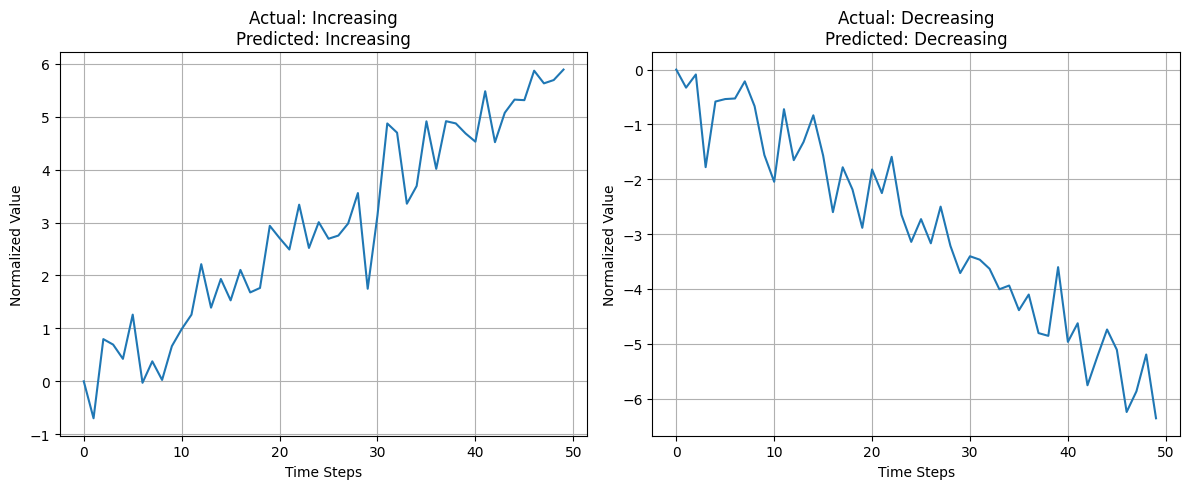


New sequence prediction completed!


In [ ]:
# Function to predict a new sequence

def predict_sequence(slope):

    start = np.random.uniform(10, 30)

    time = np.arange(sequence_length)

    values = start + slope * time

    noise = np.random.normal(0, 0.5, sequence_length)

    sequence = values + noise

    # Apply the same normalization used during training
    sequence = sequence - sequence[0]

    # Convert into tensor
    sequence = torch.tensor(
        sequence,
        dtype=torch.float32
    ).reshape(1, sequence_length, 1).to(device)

    model.eval()

    with torch.no_grad():

        output = model(sequence)

        prediction = torch.argmax(output, dim=1).item()

    return sequence.cpu().numpy()[0, :, 0], prediction


# Generate two new sequences

samples = [
    (0.12, "Increasing"),
    (-0.12, "Decreasing")
]

plt.figure(figsize=(12, 5))

for i, (slope, actual) in enumerate(samples):

    sequence, prediction = predict_sequence(slope)

    predicted_label = (
        "Decreasing" if prediction == 0 else "Increasing"
    )

    plt.subplot(1, 2, i + 1)

    plt.plot(sequence)

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted_label}"
    )

    plt.xlabel("Time Steps")
    plt.ylabel("Normalized Value")
    plt.grid(True)

    print(
        f"Actual: {actual} | Predicted: {predicted_label}"
    )

plt.tight_layout()
plt.show()

print("\nNew sequence prediction completed!")